In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# Setup

In [54]:
historyCall_path = "../../data/historyCalls/raw/historyCalls.csv"
historyCall_df = pd.read_csv(historyCall_path, sep=";")
historyCall_df.head()


C:\Users\S_YZH\AppData\Local\Temp\ipykernel_25064\2772085524.py:2: DtypeWarning: Columns (0: intercomConversationId, 1: intercomCallerNumber) have mixed types. Specify dtype option on import or set low_memory=False.
  historyCall_df = pd.read_csv(historyCall_path, sep=";")


,reasons,ward,clusterId,type,roomId,cancelPerson,intercomConversationId,personLocation,zone,clusterName,...,cancelTimestamp,wardId,priority,intercomCallerNumber,room,personName,cancellationTrigger,name,cancelLocation,triggeredBy
0,[],2V ZONE 2A,1032.0,Normal,71.0,429b91b1e5f922997e21479cdfaa7415ff27594ac74922...,NaN,NaN,NaN,Bed 2,...,2024-01-31T04:08:10Z,6.0,3,NaN,K 205,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b93...,InputEvent,Normale oproep,K 205,NaN
1,[],2V ZONE 2A,1126.0,Normal,89.0,429b91b1e5f922997e21479cdfaa7415ff27594ac74922...,NaN,NaN,NaN,Bed 2,...,2024-01-31T04:06:08Z,6.0,3,NaN,K 223,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b93...,InputEvent,Normale oproep,K 223,NaN
2,[],NaN,NaN,Care,NaN,caba69daba2592b14e91e749f2c6c3f6a7c4b0b9d0a034...,NaN,2V ZONE 2A,ZONE 2A,NaN,...,2024-01-31T04:21:55.0721436Z,NaN,3,NaN,NaN,caba69daba2592b14e91e749f2c6c3f6a7c4b0b9d0a034...,InputEvent,Draadloze oproep,2A_K 221,NaN
3,[],2V ZONE 2A,NaN,Normal,83.0,b49560dc6e0ffe0b7abc6a018ecde994d0c1b1e571464d...,NaN,NaN,NaN,NaN,...,2024-01-31T05:10:22Z,6.0,3,NaN,K 217,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b93...,InputEvent,Normale oproep,K 217,NaN
4,[],NaN,NaN,Care,NaN,6ba2e0fb8d826021563d2bab9489a0dea5d0046ea49c7e...,NaN,2V ZONE 2B,ZONE 2B,NaN,...,2024-01-31T05:24:06.5463461Z,NaN,3,NaN,NaN,6ba2e0fb8d826021563d2bab9489a0dea5d0046ea49c7e...,InputEvent,Draadloze oproep,2B_K 233,NaN


In [6]:
historyCall_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 37225 entries, 0 to 37224
Data columns (total 27 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   reasons                 37225 non-null  str    
 1   ward                    31263 non-null  str    
 2   clusterId               12293 non-null  float64
 3   type                    37225 non-null  str    
 4   roomId                  16474 non-null  float64
 5   cancelPerson            37225 non-null  str    
 6   intercomConversationId  31 non-null     str    
 7   personLocation          21314 non-null  str    
 8   zone                    20531 non-null  str    
 9   clusterName             12293 non-null  str    
 10  id                      37225 non-null  int64  
 11  justification           0 non-null      float64
 12  personType              22159 non-null  str    
 13  timestamp               37225 non-null  str    
 14  area                    20660 non-null  str    
 

# Exploratory analysis (EDA)

In [22]:
# check nan values percentage functions
def check_nan_percentage(df, threshold=50):
    nan_summary = df.isna().sum().sort_values(ascending=False)
    nan_summary_percent = (nan_summary / len(df) * 100).round(2).sort_values(ascending=False)
    nan_summary_df = pd.DataFrame({
        'column': nan_summary.index,
        'nan_count': nan_summary.values,
        'nan_percent': nan_summary_percent.values
    })
    print("\nNaN Summary:")
    print(nan_summary_df)

check_nan_percentage(historyCall_df, threshold=50)


NaN Summary:
                    column  nan_count  nan_percent
0            justification      37225       100.00
1         annotationPerson      37225       100.00
2   intercomConversationId      37194        99.92
3     intercomCallerNumber      37194        99.92
4              clusterName      24932        66.98
5                clusterId      24932        66.98
6                   roomId      20751        55.74
7                     room      20751        55.74
8                     zone      16694        44.85
9                     area      16565        44.50
10          personLocation      15911        42.74
11              personType      15066        40.47
12                    ward       5962        16.02
13                  wardId       5962        16.02
14          cancelLocation        560         1.50
15         cancelTimestamp        405         1.09
16     cancellationTrigger        405         1.09
17             triggeredBy        241         0.65
18               

In [55]:
# remove columns with more than 60% nan values
threshold = 60
nan_summary = historyCall_df.isna().sum()
nan_summary_percent = (nan_summary / len(historyCall_df) * 100).round(2)
columns_to_drop = nan_summary_percent[nan_summary_percent > threshold].index
historyCall_df_cleaned = historyCall_df.drop(columns=columns_to_drop)
print(f"\ncolumns dropped: {list(columns_to_drop)}")

# drop reasons column
historyCall_df_cleaned = historyCall_df_cleaned.drop(columns=['reasons'])

# drop roomId column
historyCall_df_cleaned = historyCall_df_cleaned.drop(columns=['roomId'])

print(f"\nshape of cleaned DataFrame: {historyCall_df_cleaned.shape}")

# percentage of missing values in each column after cleaning
nan_summary_cleaned = historyCall_df_cleaned.isna().sum().sort_values(ascending=False)
nan_summary_cleaned_percent = (nan_summary_cleaned / len(historyCall_df_cleaned) * 100).round(2).sort_values(ascending=False)
nan_summary_cleaned_df = pd.DataFrame({ 
    'column': nan_summary_cleaned.index,
    'nan_count': nan_summary_cleaned.values,
    'nan_percent': nan_summary_cleaned_percent.values
})
print("\nNaN Summary after cleaning:")
print(nan_summary_cleaned_df)

historyCall_df_cleaned.info()





columns dropped: ['clusterId', 'intercomConversationId', 'clusterName', 'justification', 'annotationPerson', 'intercomCallerNumber']

shape of cleaned DataFrame: (37225, 19)

NaN Summary after cleaning:
                 column  nan_count  nan_percent
0                  room      20751        55.74
1                  zone      16694        44.85
2                  area      16565        44.50
3        personLocation      15911        42.74
4            personType      15066        40.47
5                  ward       5962        16.02
6                wardId       5962        16.02
7        cancelLocation        560         1.50
8       cancelTimestamp        405         1.09
9   cancellationTrigger        405         1.09
10          triggeredBy        241         0.65
11                 name         74         0.20
12                 type          0         0.00
13         cancelPerson          0         0.00
14                   id          0         0.00
15         responseTime     

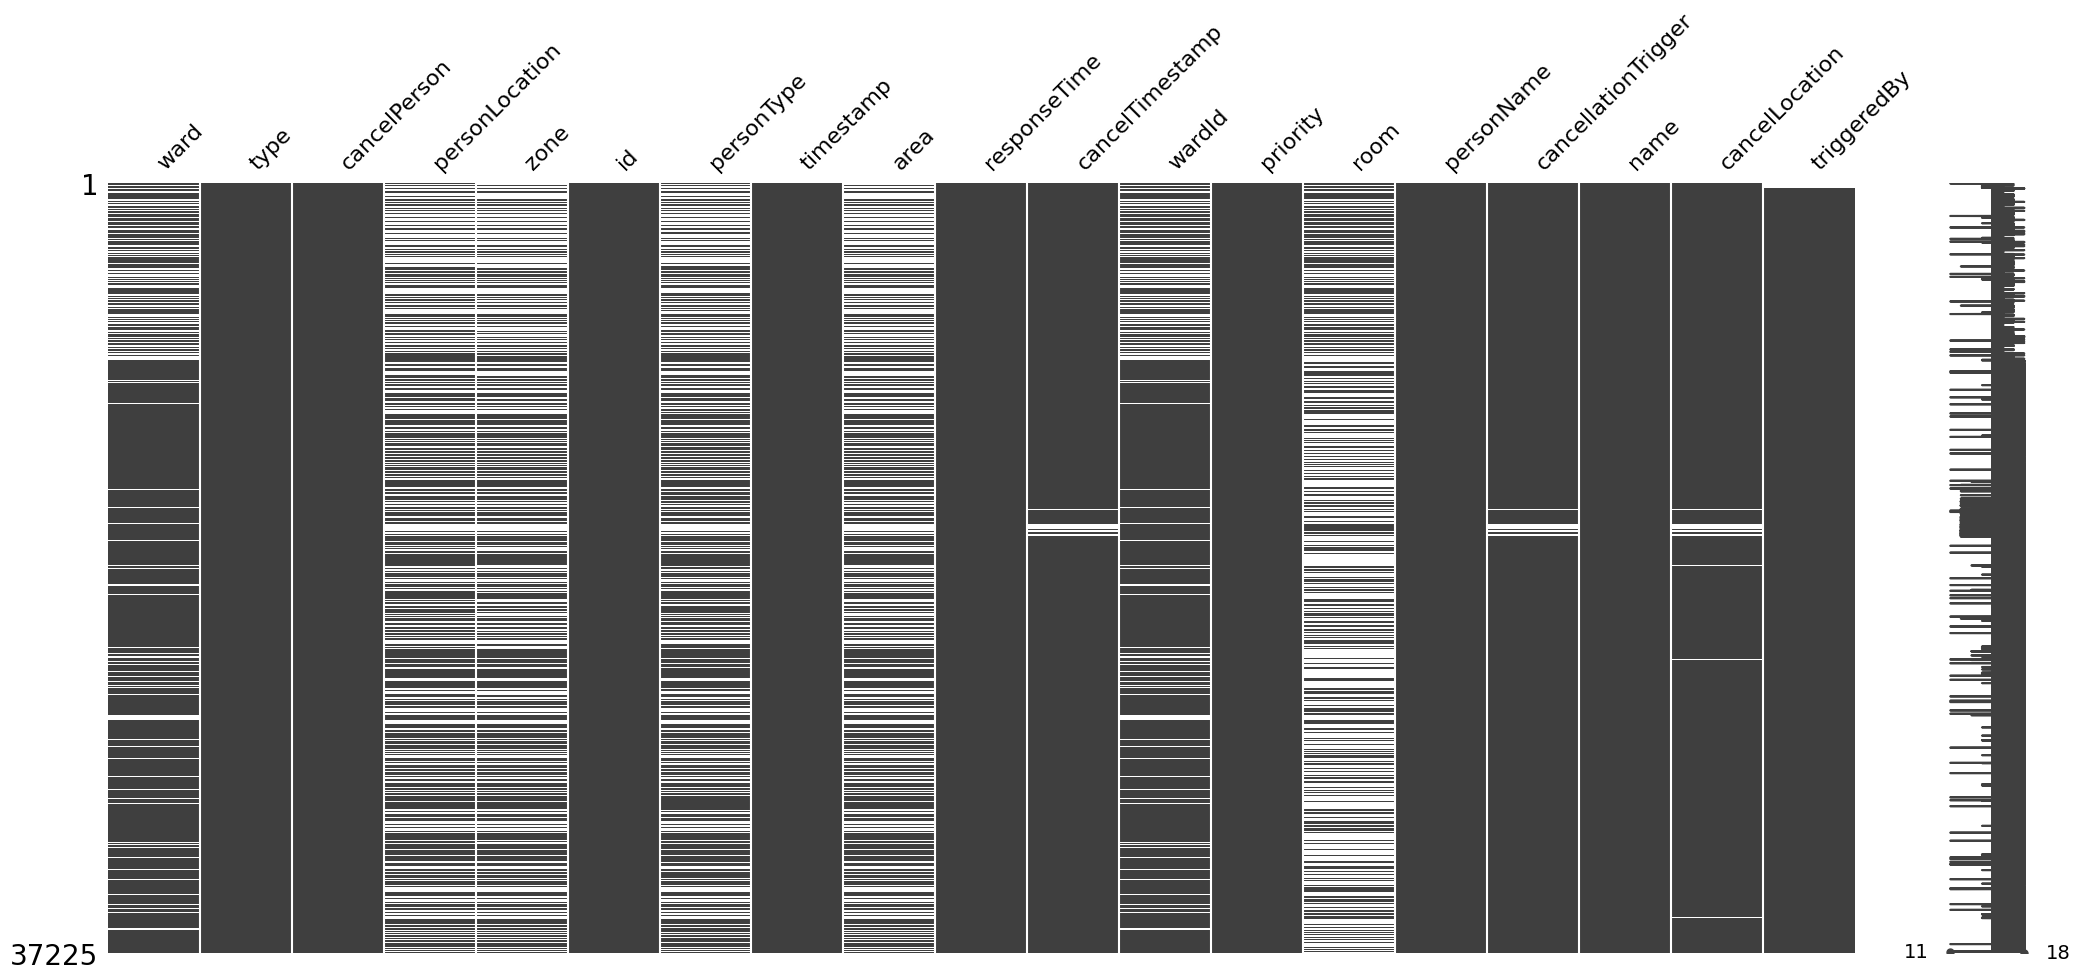

In [24]:
msno.matrix(historyCall_df_cleaned)
plt.show()

In [56]:
# fill wardId with -1 when its value is nan, fill ward with "unknown" when its value is nan
historyCall_df_cleaned['wardId'] = historyCall_df_cleaned['wardId'].fillna(-1)
historyCall_df_cleaned['ward'] = historyCall_df_cleaned['ward'].fillna("unknown")
historyCall_df_cleaned['room'] = historyCall_df_cleaned['room'].fillna("unknown")
historyCall_df_cleaned['zone'] = historyCall_df_cleaned['zone'].fillna("unknown")
historyCall_df_cleaned['area'] = historyCall_df_cleaned['area'].fillna("unknown")
historyCall_df_cleaned['personLocation'] = historyCall_df_cleaned['personLocation'].fillna("unknown")
historyCall_df_cleaned['personType'] = historyCall_df_cleaned['personType'].fillna("Unknown")
historyCall_df_cleaned['ward'] = historyCall_df_cleaned['ward'].replace('n/a', 'Unknown')

historyCall_df_cleaned['is_cancelled'] = historyCall_df_cleaned['cancelTimestamp'].notna()

# check nan value percentage of historyCall_df_cleaned after filling nan values
nan_summary_filled = historyCall_df_cleaned.isna().sum().sort_values(ascending=False)
nan_summary_filled_percent = (nan_summary_filled / len(historyCall_df_cleaned) * 100).round(2).sort_values(ascending=False)
nan_summary_filled_df = pd.DataFrame({      
    'column': nan_summary_filled.index,
    'nan_count': nan_summary_filled.values,
    'nan_percent': nan_summary_filled_percent.values
})
print("\nNaN summary")
print(nan_summary_filled_df)




NaN summary
                 column  nan_count  nan_percent
0        cancelLocation        560         1.50
1       cancelTimestamp        405         1.09
2   cancellationTrigger        405         1.09
3           triggeredBy        241         0.65
4                  name         74         0.20
5          cancelPerson          0         0.00
6                  type          0         0.00
7                  ward          0         0.00
8        personLocation          0         0.00
9                  zone          0         0.00
10           personType          0         0.00
11                   id          0         0.00
12               wardId          0         0.00
13         responseTime          0         0.00
14                 area          0         0.00
15            timestamp          0         0.00
16           personName          0         0.00
17                 room          0         0.00
18             priority          0         0.00
19         is_cancelled    

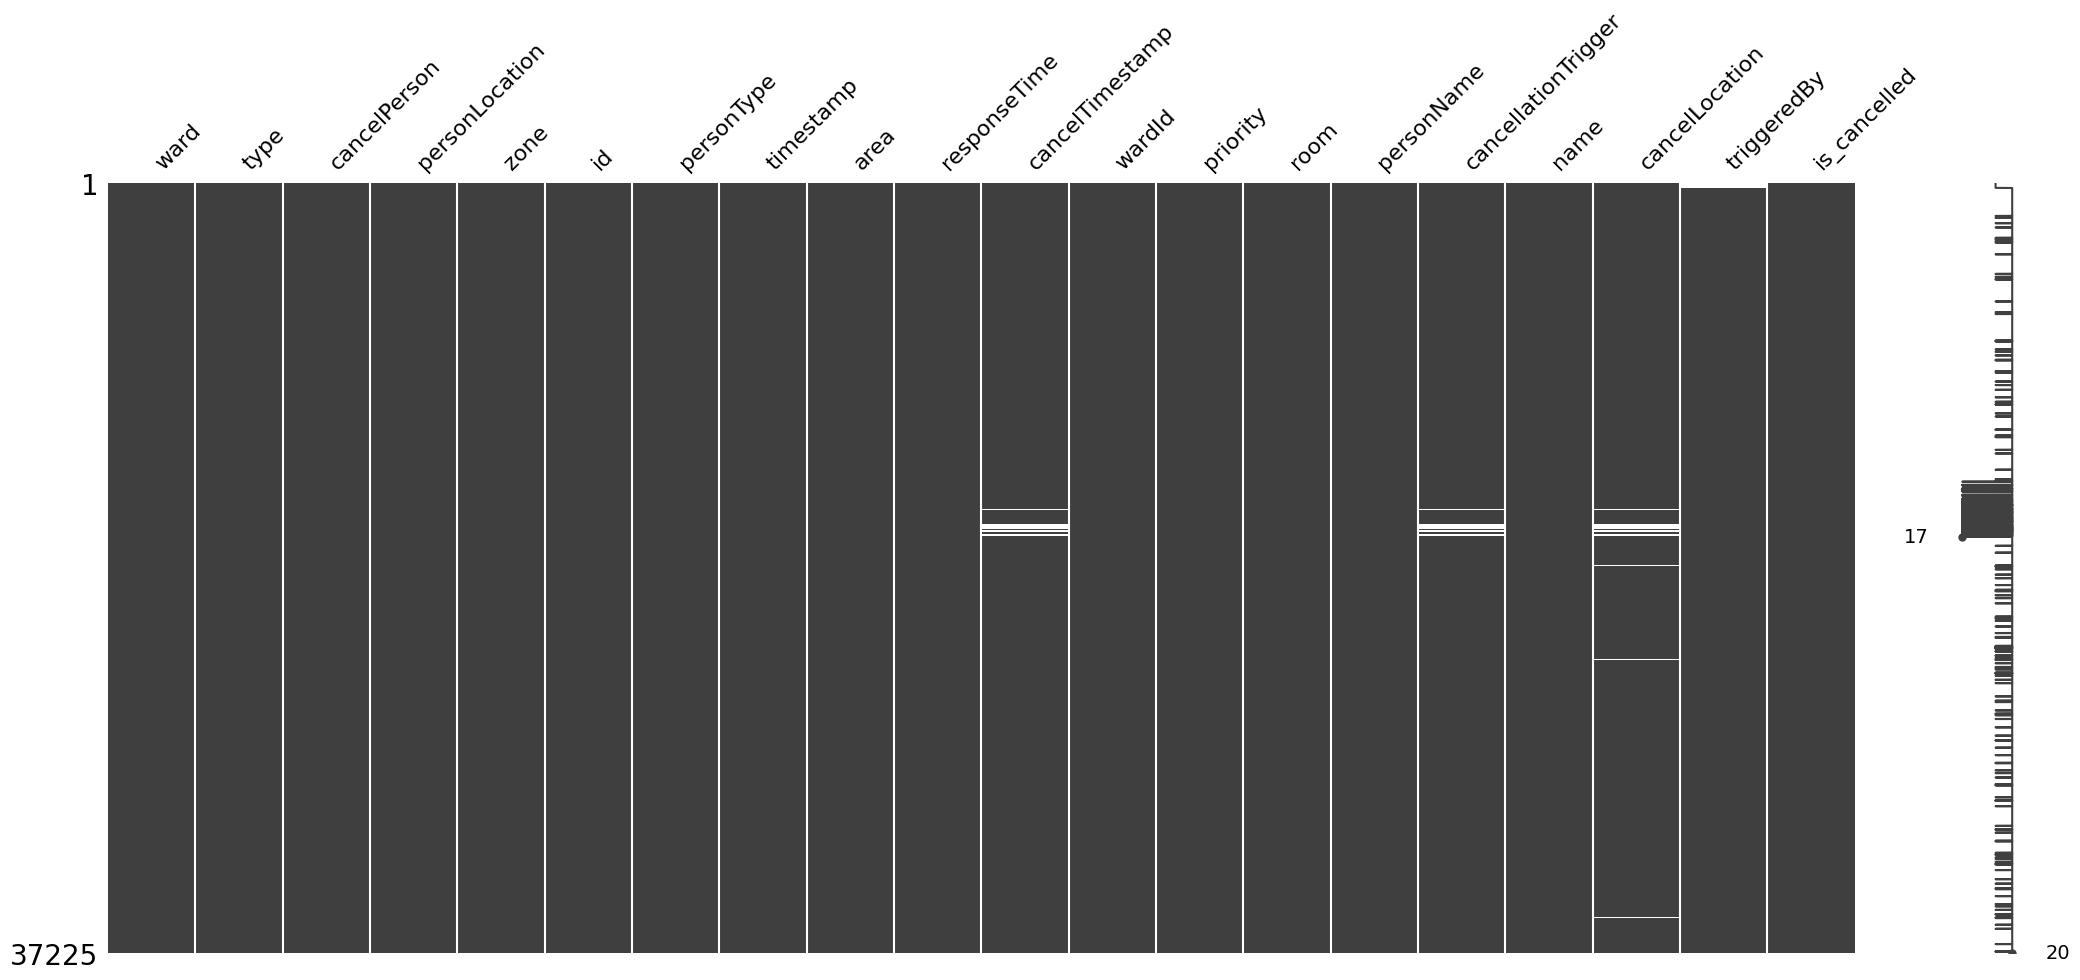

In [37]:
msno.matrix(historyCall_df_cleaned)
plt.show()

# Data cleaning

fix timestamp 

In [62]:
# parse and validate timestamps (robust mixed ISO8601 handling)
historyCall_df_cleaned['timestamp'] = pd.to_datetime(
    historyCall_df_cleaned['timestamp'], format='ISO8601', utc=True, errors='coerce'
)
historyCall_df_cleaned['cancelTimestamp'] = pd.to_datetime(
    historyCall_df_cleaned['cancelTimestamp'], format='ISO8601', utc=True, errors='coerce'
)

print(f"timestamp NaT after parsing: {historyCall_df_cleaned['timestamp'].isna().sum()}")
print(f"cancelTimestamp NaT after parsing: {historyCall_df_cleaned['cancelTimestamp'].isna().sum()}")

# invalid cancellation timestamps to fix (cancelTimestamp < timestamp)
invalid_mask = (
    historyCall_df_cleaned['timestamp'].notna()
    & historyCall_df_cleaned['cancelTimestamp'].notna()
    & (historyCall_df_cleaned['cancelTimestamp'] < historyCall_df_cleaned['timestamp'])
)
invalid_count = invalid_mask.sum()
historyCall_df_cleaned.loc[invalid_mask, 'cancelTimestamp'] = pd.NaT
print(f"fixed {invalid_count} invalid cancelTimestamps (cancel < start)")

# cancellation consistency: if no cancelTimestamp, cancellation detail columns should be empty
not_cancelled_mask = historyCall_df_cleaned['cancelTimestamp'].isna()
for col in ['cancellationTrigger', 'triggeredBy', 'cancelLocation']:
    historyCall_df_cleaned.loc[not_cancelled_mask, col] = pd.NA

# derive cancellation flag after all timestamp fixes
historyCall_df_cleaned['is_cancelled'] = historyCall_df_cleaned['cancelTimestamp'].notna()

# remove duplicates
before = len(historyCall_df_cleaned)
historyCall_df_cleaned = historyCall_df_cleaned.drop_duplicates(subset=['id'], keep='first')
print(f"Removed {before - len(historyCall_df_cleaned)} duplicate rows")

historyCall_df_cleaned['timestamp']

timestamp NaT after parsing: 0
cancelTimestamp NaT after parsing: 412
fixed 0 invalid cancelTimestamps (cancel < start)
Removed 0 duplicate rows


0                 2024-01-31 03:49:14+00:00
1                 2024-01-31 03:51:47+00:00
2       2024-01-31 04:21:31.109643100+00:00
3                 2024-01-31 04:57:18+00:00
4       2024-01-31 05:20:51.108499700+00:00
                        ...                
37220   2024-08-26 10:15:37.171956800+00:00
37221   2024-08-26 10:16:34.188893900+00:00
37222   2024-08-26 10:19:20.050745800+00:00
37223             2024-08-26 10:47:46+00:00
37224             2024-08-26 11:13:40+00:00
Name: timestamp, Length: 37225, dtype: datetime64[ns, UTC]

In [63]:
# extract time features from timestamp
historyCall_df_cleaned['date'] = historyCall_df_cleaned['timestamp'].dt.date
historyCall_df_cleaned['hour'] = historyCall_df_cleaned['timestamp'].dt.hour
historyCall_df_cleaned['dayofweek'] = historyCall_df_cleaned['timestamp'].dt.dayofweek  # monday=0, sunday=6

# create shift feature
def assign_shift(hour):
    if pd.isna(hour):
        return None
    if 7 <= hour <= 14:
        return 'day'
    elif 15 <= hour <= 22:
        return 'evening'
    else:
        return 'night'

historyCall_df_cleaned['shift'] = historyCall_df_cleaned['hour'].apply(assign_shift)

# date range
valid_dates = historyCall_df_cleaned['date'].dropna()
print(f"date range: {valid_dates.min()} to {valid_dates.max()}")
print(f"\nshift distribution:")
print(historyCall_df_cleaned['shift'].value_counts())
print(f"\nday of week distribution:")
print(historyCall_df_cleaned['dayofweek'].value_counts().sort_index())
print(f"\nsample:")
print(historyCall_df_cleaned[['timestamp', 'date', 'hour', 'dayofweek', 'shift']].head())

date range: 2024-01-31 to 2024-08-26

shift distribution:
shift
day        15320
evening    13106
night       8799
Name: count, dtype: int64

day of week distribution:
dayofweek
0    5242
1    5234
2    5356
3    5478
4    5396
5    5441
6    5078
Name: count, dtype: int64

sample:
                            timestamp        date  hour  dayofweek  shift
0           2024-01-31 03:49:14+00:00  2024-01-31     3          2  night
1           2024-01-31 03:51:47+00:00  2024-01-31     3          2  night
2 2024-01-31 04:21:31.109643100+00:00  2024-01-31     4          2  night
3           2024-01-31 04:57:18+00:00  2024-01-31     4          2  night
4 2024-01-31 05:20:51.108499700+00:00  2024-01-31     5          2  night


durition features(call_duration_sec / staying_time)

In [64]:
# staying_time in seconds
historyCall_df_cleaned['staying_time'] = (
    historyCall_df_cleaned['cancelTimestamp'] - historyCall_df_cleaned['timestamp']
).dt.total_seconds()

print(f"calls with staying_time: {historyCall_df_cleaned['staying_time'].notna().sum():,}")
print(f"calls without staying_time which not cancelled: {historyCall_df_cleaned['staying_time'].isna().sum():,}")

duration_data = historyCall_df_cleaned[historyCall_df_cleaned['staying_time'].notna()]
if len(duration_data) > 0:
    print(f"\nstaying time statistics:")
    print(duration_data['staying_time'].describe())
    
    # negative durations
    negative = (duration_data['staying_time'] < 0).sum()
    if negative > 0:
        print(f"WARNING: {negative} negative durations found!")
    
    # convert duration in minutes
    historyCall_df_cleaned['staying_time_minutes'] = historyCall_df_cleaned['staying_time'] / 60
    print(f"\nstaying time - sample stats:")
    print(f"  mean: {duration_data['staying_time'].mean() / 60:.2f} min")
    print(f"  median: {duration_data['staying_time'].median() / 60:.2f} min")
    print(f"  max: {duration_data['staying_time'].max() / 60:.2f} min")

calls with staying_time: 36,813
calls without staying_time which not cancelled: 412

staying time statistics:
count    3.681300e+04
mean     1.158305e+03
std      2.784509e+04
min      0.000000e+00
25%      1.369715e+02
50%      3.340000e+02
75%      6.720000e+02
max      3.384665e+06
Name: staying_time, dtype: float64

staying time - sample stats:
  mean: 19.31 min
  median: 5.57 min
  max: 56411.09 min


save cleaned dataset to interim

In [65]:
# strict pre-save quality gates
required_cols = [
    'id', 'timestamp', 'cancelTimestamp', 'is_cancelled',
    'cancellationTrigger', 'triggeredBy', 'cancelLocation'
 ]
missing_required = [c for c in required_cols if c not in historyCall_df_cleaned.columns]
if missing_required:
    raise ValueError(f"Missing required columns before save: {missing_required}")

duplicate_count = int(historyCall_df_cleaned['id'].duplicated().sum())
if duplicate_count > 0:
    raise ValueError(f"Duplicate ids detected: {duplicate_count}")

timestamp_nat_count = int(historyCall_df_cleaned['timestamp'].isna().sum())
if timestamp_nat_count > 0:
    raise ValueError(f"timestamp contains NaT rows: {timestamp_nat_count}")

cancel_mismatch = int((
    historyCall_df_cleaned['is_cancelled'] != historyCall_df_cleaned['cancelTimestamp'].notna()
).sum())
if cancel_mismatch > 0:
    raise ValueError(f"is_cancelled mismatch with cancelTimestamp.notna(): {cancel_mismatch}")

detail_cols = ['cancellationTrigger', 'triggeredBy', 'cancelLocation']
not_cancelled = historyCall_df_cleaned['cancelTimestamp'].isna()
for col in detail_cols:
    inconsistent = int((not_cancelled & historyCall_df_cleaned[col].notna()).sum())
    if inconsistent > 0:
        raise ValueError(f"{col} has {inconsistent} values while cancelTimestamp is missing")

# duration sanity gate
staying_time_check = (
    historyCall_df_cleaned['cancelTimestamp'] - historyCall_df_cleaned['timestamp']
).dt.total_seconds()
negative_durations = int((staying_time_check < 0).sum())
if negative_durations > 0:
    raise ValueError(f"Negative staying_time rows detected: {negative_durations}")

interim_path = "../../data/historyCalls/interim/historyCalls_cleaned.csv"
try:
    historyCall_df_cleaned.to_csv(interim_path, sep=";", index=False)
    saved_path = interim_path
except PermissionError:
    fallback_path = f"../../data/historyCalls/interim/historyCalls_cleaned_{pd.Timestamp.now('UTC').strftime('%Y%m%d_%H%M%S')}.csv"
    historyCall_df_cleaned.to_csv(fallback_path, sep=";", index=False)
    saved_path = fallback_path
    print(f"target file locked; saved fallback instead: {fallback_path}")

print(f"saved {len(historyCall_df_cleaned):,} rows to {saved_path}")

# verify save
test_load = pd.read_csv(saved_path, sep=";")
print(f"verified: loaded {len(test_load):,} rows from saved file")

target file locked; saved fallback instead: ../../data/historyCalls/interim/historyCalls_cleaned_20260223_122413.csv
saved 37,225 rows to ../../data/historyCalls/interim/historyCalls_cleaned_20260223_122413.csv
verified: loaded 37,225 rows from saved file


In [95]:
# Function to calculate type-specific outlier thresholds
def calculate_type_outlier_summary(df, duration_col='staying_time', type_col='type', iqr_multiplier=1.5):
    summary = []
    
    for call_type in sorted(df[type_col].unique()):
        type_data = df[df[type_col] == call_type]
        duration_data = type_data[duration_col].dropna()
        
        if len(duration_data) > 0:
            q1 = duration_data.quantile(0.25)
            q3 = duration_data.quantile(0.75)
            iqr = q3 - q1
            outlier_threshold = q3 + (iqr_multiplier * iqr)
            
            outlier_count = (duration_data > outlier_threshold).sum()
            outlier_pct = (outlier_count / len(duration_data) * 100)
            
            summary.append({
                'type': call_type,
                'total rows': len(type_data),
                'duration': len(duration_data),
                'mean (min)': duration_data.mean() / 60,
                'median (min)': duration_data.median() / 60,
                'max (min)': duration_data.max() / 60,
                'outlier threshold': outlier_threshold,
                'outliers count': outlier_count,
                'outlier': outlier_pct
            })
    
    return pd.DataFrame(summary)


type_summary_df = calculate_type_outlier_summary(historyCall_df_cleaned)

print(type_summary_df.to_string(index=False))

              type  total rows  duration  mean (min)  median (min)    max (min)  outlier threshold  outliers count   outlier
        Assistance         723       720   40.662146      1.616667  8577.137434         976.301139              70  9.722222
              Care       19718     19552    9.749571      6.645198  1292.478378        1583.021849            1101  5.631137
        LowBattery         281       274   35.352183     14.982577   481.156675        4711.910907              17  6.204380
            Normal       12879     12692   25.922744      4.900000 28833.922896        1368.322121             774  6.098330
             Panic          19        19  275.724881      0.179226  3516.527972         146.600871               4 21.052632
           PullOut        1015       998    4.544142      0.925000    77.333333         782.625000              93  9.318637
          Sanitary        1291      1273   26.412470      3.683333  7061.200000         984.000000              77  6.048704


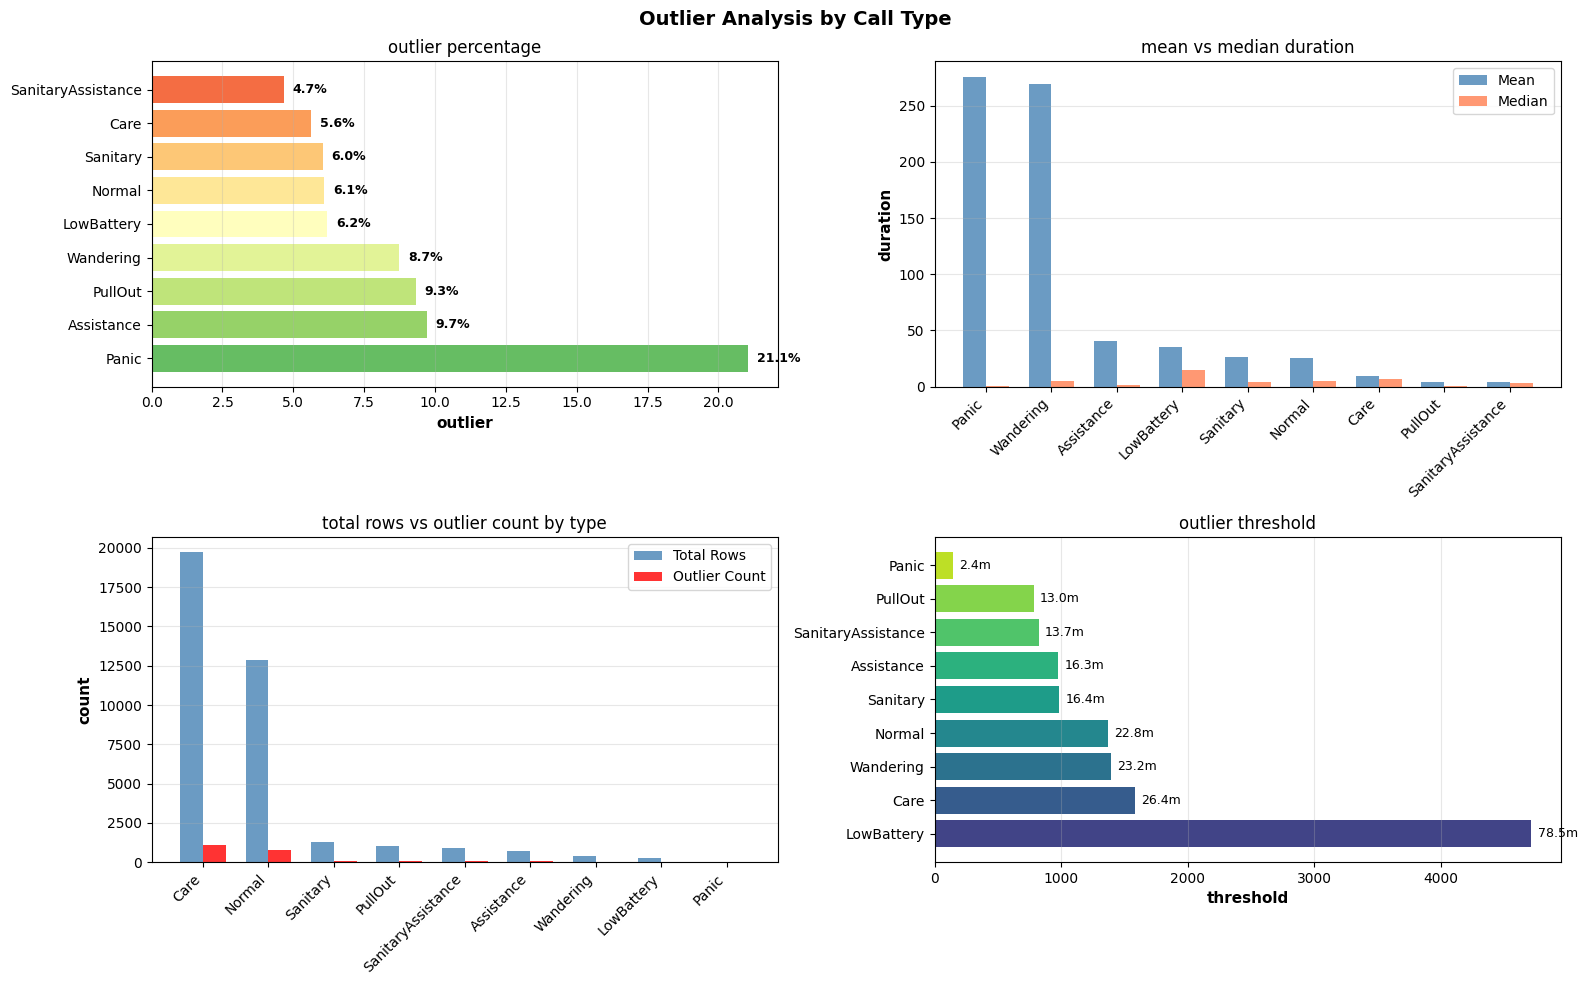

In [98]:
def plot_type_outlier_analysis(summary_df, title='Outlier Analysis by Call Type', figsize=(16, 10)):
    
    fig, axes = plt.subplots(2, 2, figsize=figsize)
    fig.suptitle(title, fontsize=14, fontweight='bold')
    
    # outlier percentage
    ax1 = axes[0, 0]
    sorted_by_outlier = summary_df.sort_values('outlier', ascending=False)
    colors1 = plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, len(sorted_by_outlier)))
    bars1 = ax1.barh(sorted_by_outlier['type'], sorted_by_outlier['outlier'], color=colors1)
    ax1.set_xlabel('outlier', fontsize=11, fontweight='bold')
    ax1.set_title('outlier percentage', fontsize=12)
    ax1.grid(axis='x', alpha=0.3)
    for i, (idx, row) in enumerate(sorted_by_outlier.iterrows()):
        ax1.text(row['outlier'] + 0.3, i, f"{row['outlier']:.1f}%", 
                 va='center', fontsize=9, fontweight='bold')
    
    # mean vs median duration
    ax2 = axes[0, 1]
    sorted_by_mean = summary_df.sort_values('mean (min)', ascending=False)
    x_pos = np.arange(len(sorted_by_mean))
    width = 0.35
    bars_mean = ax2.bar(x_pos - width/2, sorted_by_mean['mean (min)'], width, 
                        label='Mean', color='steelblue', alpha=0.8)
    bars_median = ax2.bar(x_pos + width/2, sorted_by_mean['median (min)'], width, 
                          label='Median', color='coral', alpha=0.8)
    ax2.set_ylabel('duration', fontsize=11, fontweight='bold')
    ax2.set_title('mean vs median duration', fontsize=12)
    ax2.set_xticks(x_pos)
    ax2.set_xticklabels(sorted_by_mean['type'], rotation=45, ha='right')
    ax2.legend()
    ax2.grid(axis='y', alpha=0.3)
    
    # total rows vs outliers count
    ax3 = axes[1, 0]
    sorted_by_rows = summary_df.sort_values('total rows', ascending=False)
    x_pos = np.arange(len(sorted_by_rows))
    bars_total = ax3.bar(x_pos - width/2, sorted_by_rows['total rows'], width, 
                         label='Total Rows', color='steelblue', alpha=0.8)
    bars_outliers = ax3.bar(x_pos + width/2, sorted_by_rows['outliers count'], width, 
                            label='Outlier Count', color='red', alpha=0.8)
    ax3.set_ylabel('count', fontsize=11, fontweight='bold')
    ax3.set_title('total rows vs outlier count by type', fontsize=12)
    ax3.set_xticks(x_pos)
    ax3.set_xticklabels(sorted_by_rows['type'], rotation=45, ha='right')
    ax3.legend()
    ax3.grid(axis='y', alpha=0.3)
    
    # outlier threshold
    ax4 = axes[1, 1]
    sorted_by_threshold = summary_df.sort_values('outlier threshold', ascending=False)
    colors4 = plt.cm.viridis(np.linspace(0.2, 0.9, len(sorted_by_threshold)))
    bars4 = ax4.barh(sorted_by_threshold['type'], sorted_by_threshold['outlier threshold'], color=colors4)
    ax4.set_xlabel('threshold', fontsize=11, fontweight='bold')
    ax4.set_title('outlier threshold', fontsize=12)
    ax4.grid(axis='x', alpha=0.3)
    for i, (idx, row) in enumerate(sorted_by_threshold.iterrows()):
        threshold_min = row['outlier threshold'] / 60
        ax4.text(row['outlier threshold'] + 50, i, f'{threshold_min:.1f}m', 
                 va='center', fontsize=9)
    
    plt.tight_layout()
    plt.show()

plot_type_outlier_analysis(type_summary_df)

In [100]:
# helper function
def plot_type_boxplot(ax, duration_data, call_type, show_legend=False, iqr_multiplier=1.5):
    if len(duration_data) == 0:
        ax.text(0.5, 0.5, f'No data for {call_type}', ha='center', va='center',
               transform=ax.transAxes)
        ax.set_title(f'{call_type}', fontsize=11, fontweight='bold')
        return
    
    # outlier threshold
    q1 = duration_data.quantile(0.25)
    q3 = duration_data.quantile(0.75)
    iqr = q3 - q1
    outlier_threshold = q3 + (iqr_multiplier * iqr)
    
    # separate outliers and normal values
    outliers_mask = duration_data > outlier_threshold
    normal_vals = duration_data[~outliers_mask]
    outlier_vals = duration_data[outliers_mask]
    
    bp = ax.boxplot([duration_data], labels=[call_type], patch_artist=True,
                    widths=0.5, showfliers=False)
    
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)
    for median in bp['medians']:
        median.set(color='darkred', linewidth=2)
    
    if len(normal_vals) > 0:
        ax.scatter([1] * len(normal_vals), normal_vals, alpha=0.4, s=30, 
                  color='steelblue', label='Normal', zorder=3)
    if len(outlier_vals) > 0:
        ax.scatter([1] * len(outlier_vals), outlier_vals, alpha=0.8, s=50, 
                  color='red', marker='X', label='Outlier', zorder=4)
    
    ax.axhline(y=outlier_threshold, color='orange', linestyle='--', linewidth=1.5, 
               alpha=0.7, label=f'Threshold: {outlier_threshold/60:.1f} min')
    
    # stats text box
    outlier_count = len(outlier_vals)
    outlier_pct = (outlier_count / len(duration_data) * 100)
    stats_text = f'n={len(duration_data)}\nNormal: {len(normal_vals)}\nOutliers: {outlier_count} ({outlier_pct:.1f}%)'
    ax.text(1.35, ax.get_ylim()[1] * 0.95, stats_text, fontsize=9, 
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    ax.set_ylabel('Staying Time (seconds)', fontsize=10)
    ax.set_title(f'{call_type}', fontsize=11, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    
    if show_legend:
        ax.legend(loc='upper left', fontsize=8)

C:\Users\S_YZH\AppData\Local\Temp\ipykernel_25064\2588610173.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([duration_data], labels=[call_type], patch_artist=True,
C:\Users\S_YZH\AppData\Local\Temp\ipykernel_25064\2588610173.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([duration_data], labels=[call_type], patch_artist=True,
C:\Users\S_YZH\AppData\Local\Temp\ipykernel_25064\2588610173.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([duration_data], labels=[call_type], patch_artist=True,
C:\Users\S_YZH\AppData\Local\Temp\ipykernel_25064\2588610173.py:20:

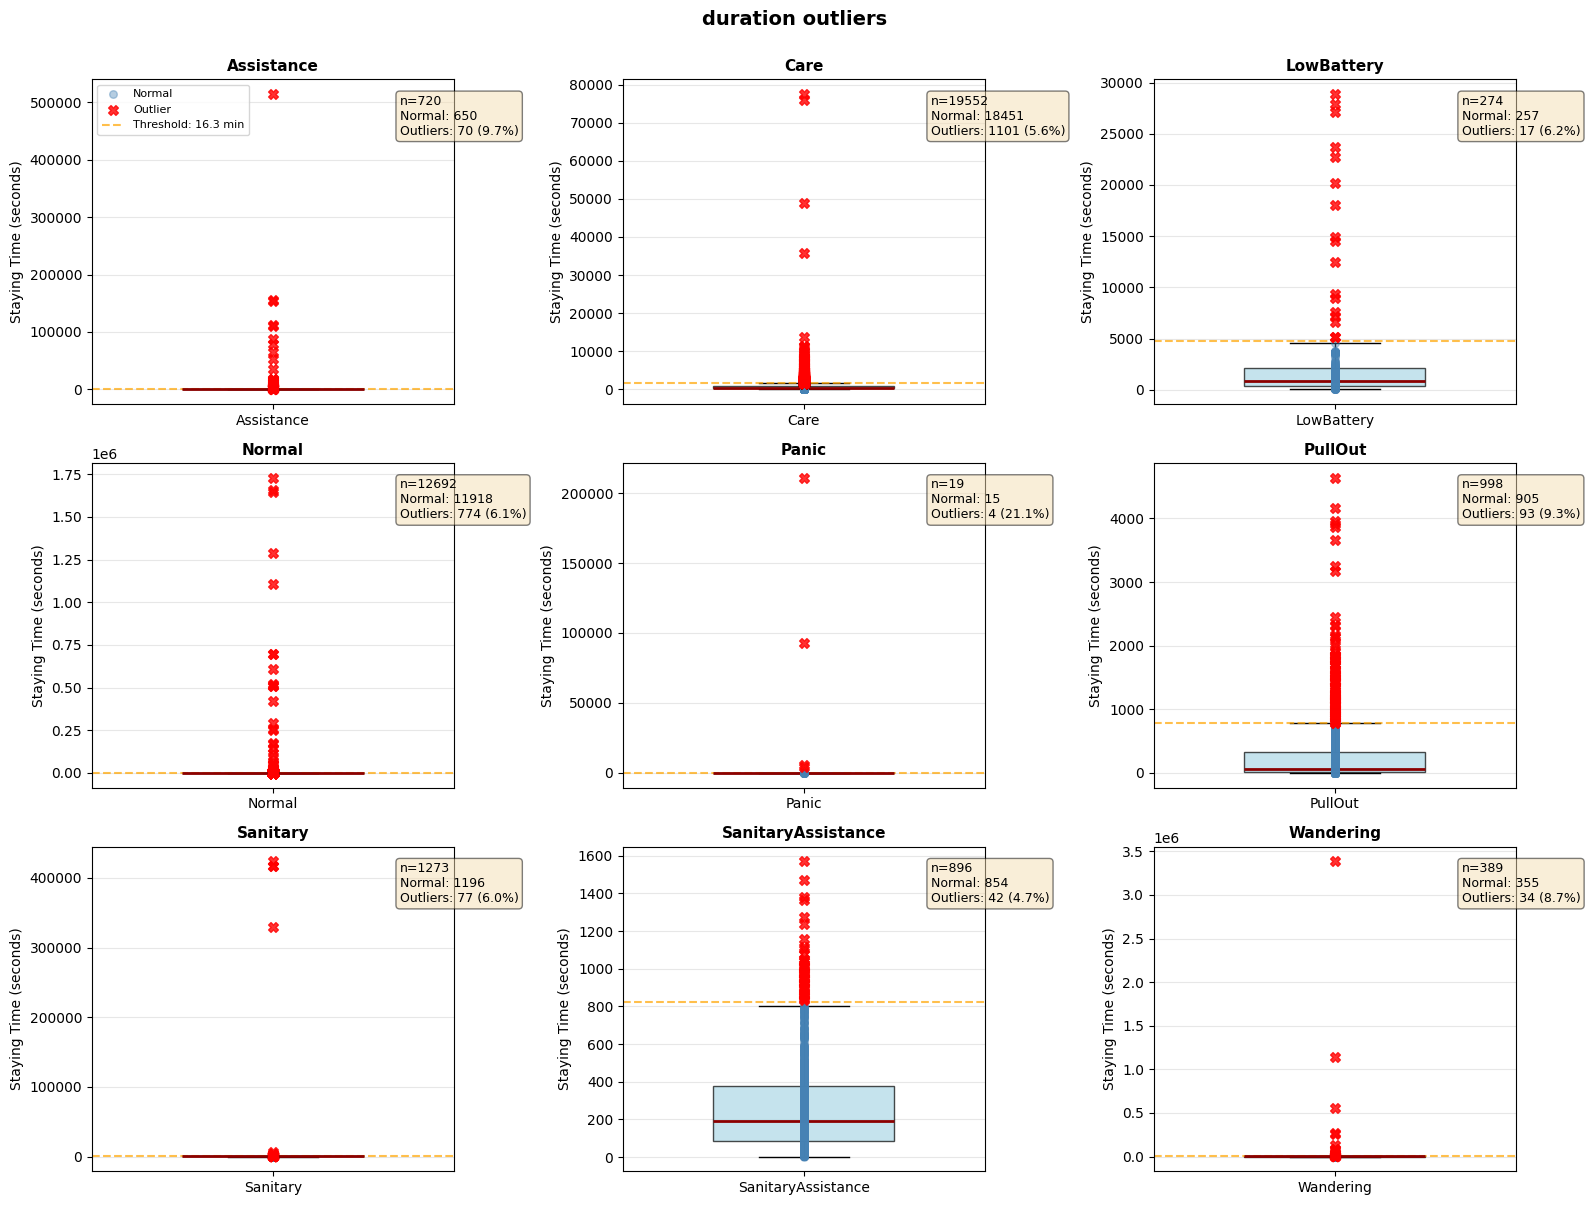

In [101]:
def plot_type_boxplot_grid(df, type_col='type', duration_col='staying_time', title='duration outliers', figsize=(16, 12), ncols=3):

    types_sorted = sorted(df[type_col].unique())
    n_types = len(types_sorted)
    nrows = (n_types + ncols - 1) // ncols
    
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = axes.flatten()
    
    for idx, call_type in enumerate(types_sorted):
        ax = axes[idx]
        type_data = df[df[type_col] == call_type]
        duration_data = type_data[duration_col].dropna()
        
        # plot individual type
        plot_type_boxplot(ax, duration_data, call_type, show_legend=(idx == 0))
    
    # remove empty subplots
    for idx in range(n_types, len(axes)):
        fig.delaxes(axes[idx])
    
    fig.suptitle(title, fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

plot_type_boxplot_grid(historyCall_df_cleaned)

1. call over time

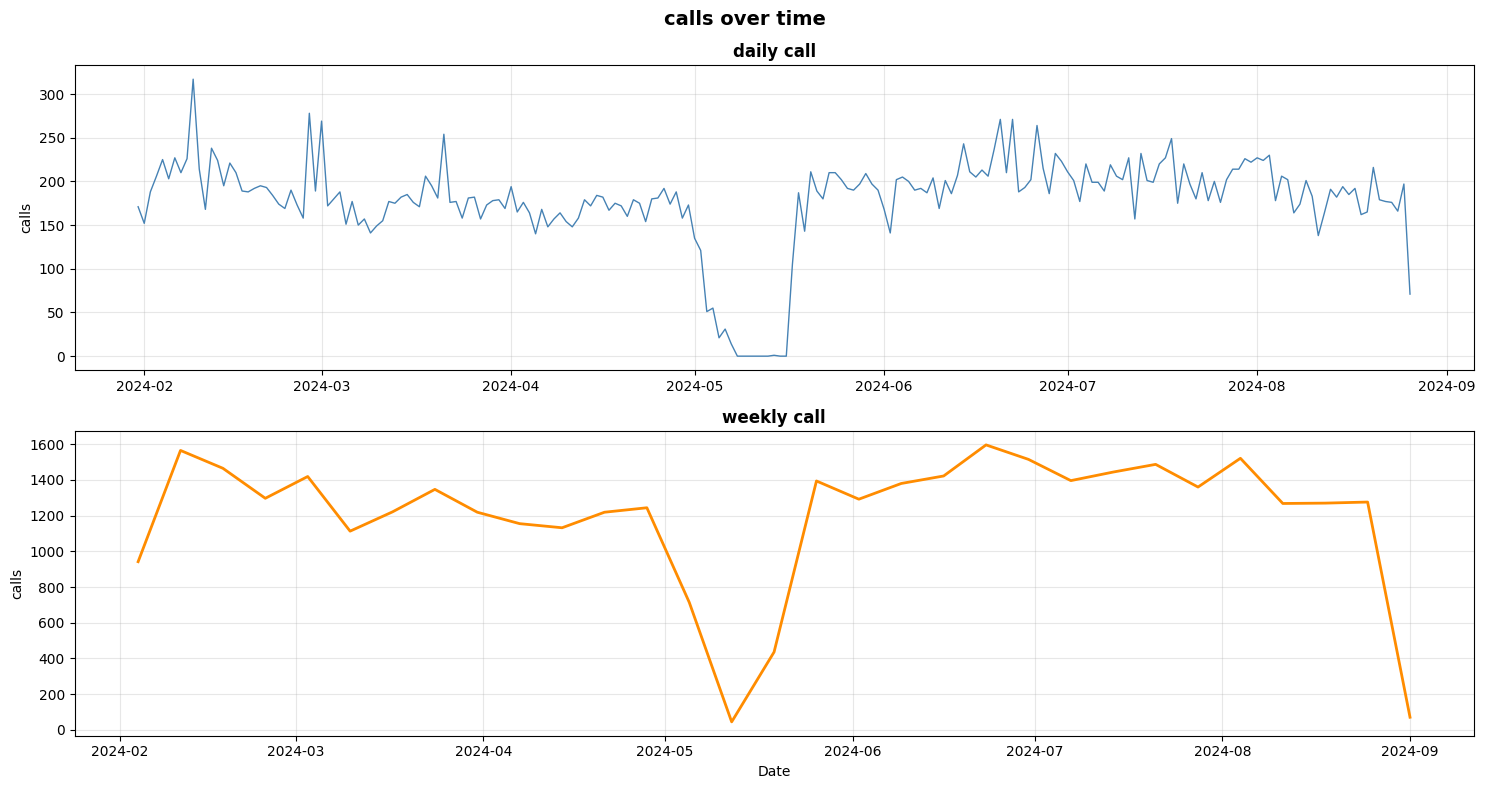

In [112]:
def prepare_calls_over_time(df, ts_col='timestamp', freq='D'):
    ts = pd.to_datetime(df[ts_col], errors='coerce', utc=True)
    series = pd.Series(1, index=ts).dropna()
    counts = series.resample(freq).sum().fillna(0)
    return counts


def plot_calls_over_time(df, ts_col='timestamp'):
    daily_counts = prepare_calls_over_time(df, ts_col=ts_col, freq='D')
    weekly_counts = prepare_calls_over_time(df, ts_col=ts_col, freq='W')

    fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=False)

    axes[0].plot(daily_counts.index, daily_counts.values, color='steelblue', linewidth=1)
    axes[0].set_title('daily call', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('calls')
    axes[0].grid(alpha=0.3)

    axes[1].plot(weekly_counts.index, weekly_counts.values, color='darkorange', linewidth=2)
    axes[1].set_title('weekly call', fontsize=12, fontweight='bold')
    axes[1].set_ylabel('calls')
    axes[1].set_xlabel('Date')
    axes[1].grid(alpha=0.3)

    plt.suptitle('calls over time', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_calls_over_time(historyCall_df_cleaned)

2. hour and weekday heatmap

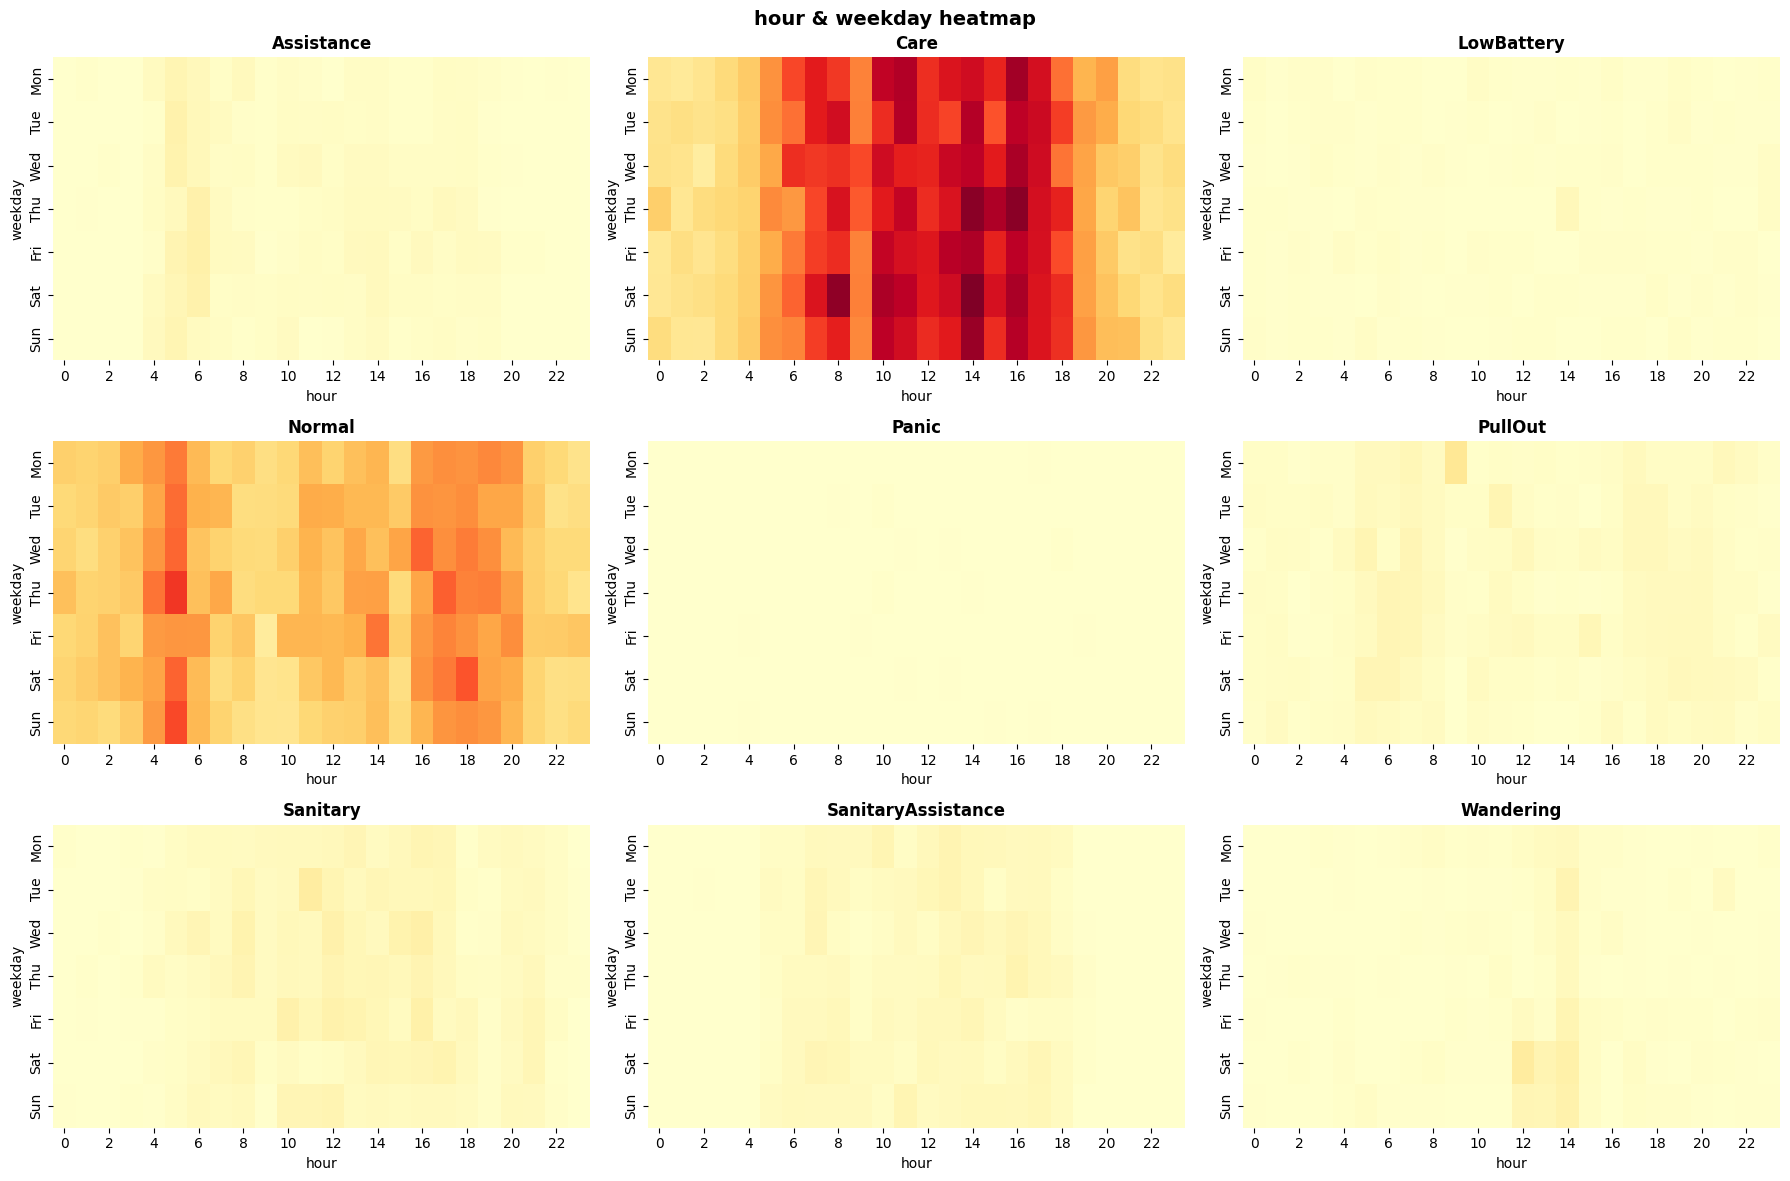

In [113]:
def prepare_hour_weekday_matrix(df, type_value, type_col='type', hour_col='hour', weekday_col='dayofweek'):
    type_df = df[df[type_col] == type_value].copy()
    pivot = pd.pivot_table(
        type_df,
        index=weekday_col,
        columns=hour_col,
        values='id',
        aggfunc='count',
        fill_value=0
    )
    pivot = pivot.reindex(index=range(7), fill_value=0)
    pivot = pivot.reindex(columns=range(24), fill_value=0)
    return pivot


def plot_hour_weekday_heatmap_by_type(df, type_col='type'):
    type_values = sorted(df[type_col].dropna().unique())
    n_types = len(type_values)
    ncols = 3
    nrows = (n_types + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    weekday_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

    vmax = 0
    matrices = {}
    for t in type_values:
        mat = prepare_hour_weekday_matrix(df, t, type_col=type_col)
        matrices[t] = mat
        vmax = max(vmax, mat.values.max())

    for idx, t in enumerate(type_values):
        ax = axes[idx]
        mat = matrices[t]
        sns.heatmap(
            mat,
            ax=ax,
            cmap='YlOrRd',
            cbar=False,
            vmin=0,
            vmax=vmax,
            xticklabels=2,
            yticklabels=weekday_labels
        )
        ax.set_title(f'{t}', fontweight='bold')
        ax.set_xlabel('hour')
        ax.set_ylabel('weekday')

    for idx in range(n_types, len(axes)):
        fig.delaxes(axes[idx])

    plt.suptitle('hour & weekday heatmap', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_hour_weekday_heatmap_by_type(historyCall_df_cleaned)

3. cancellation delay distribution

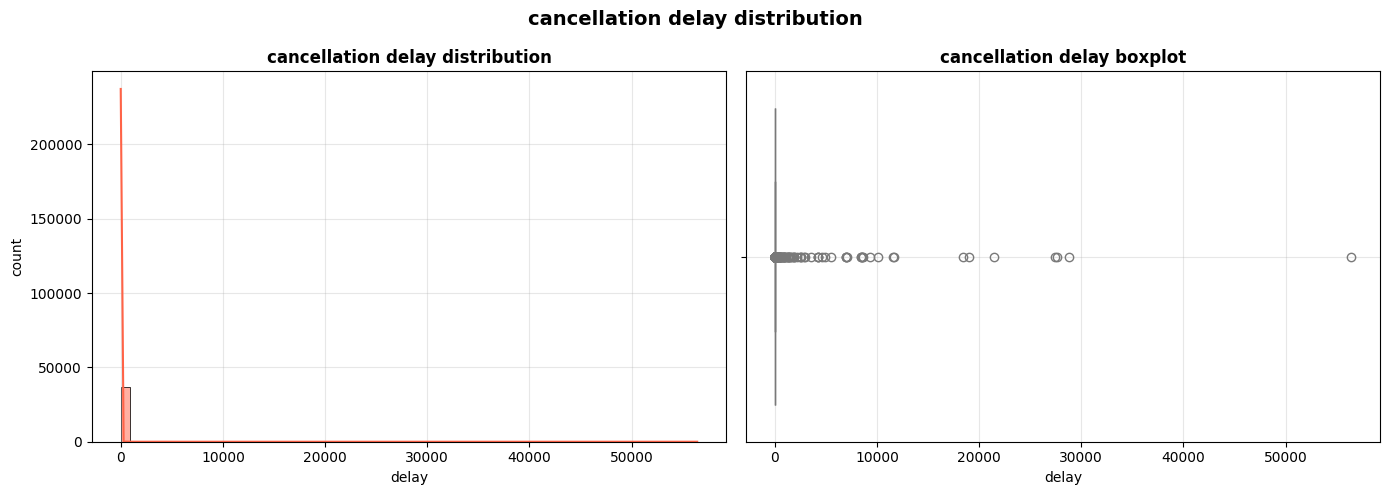

In [115]:
def get_cancellation_delay_minutes(df, cancel_flag_col='is_cancelled', duration_col='staying_time'):
    cancelled = df[df[cancel_flag_col] == True].copy()
    delay_minutes = cancelled[duration_col].dropna() / 60
    return delay_minutes


def plot_cancellation_delay_distribution(df):
    delay_minutes = get_cancellation_delay_minutes(df)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.histplot(delay_minutes, bins=60, kde=True, ax=axes[0], color='tomato')
    axes[0].set_title('cancellation delay distribution', fontweight='bold')
    axes[0].set_xlabel('delay')
    axes[0].set_ylabel('count')
    axes[0].grid(alpha=0.3)

    sns.boxplot(x=delay_minutes, ax=axes[1], color='lightblue')
    axes[1].set_title('cancellation delay boxplot', fontweight='bold')
    axes[1].set_xlabel('delay')
    axes[1].grid(alpha=0.3)

    plt.suptitle('cancellation delay distribution', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_cancellation_delay_distribution(historyCall_df_cleaned)

4. shift comparison

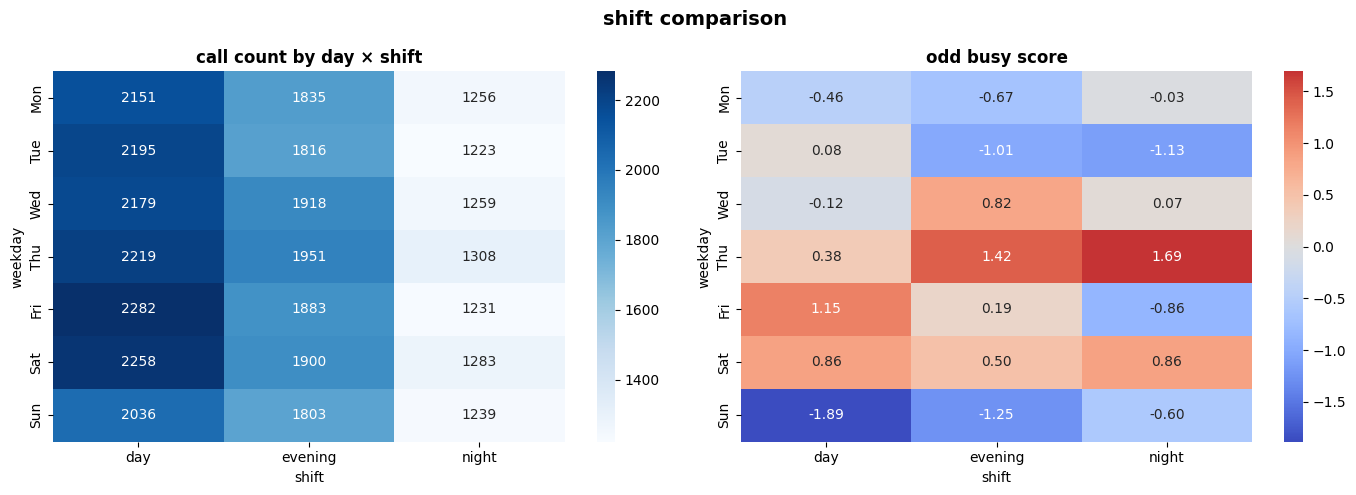

In [117]:
def prepare_shift_day_matrix(df, day_col='dayofweek', shift_col='shift'):
    pivot = pd.pivot_table(df, index=day_col, columns=shift_col, values='id', aggfunc='count', fill_value=0)
    pivot = pivot.reindex(index=range(7), fill_value=0)
    return pivot


def zscore_by_column(pivot_df):
    return (pivot_df - pivot_df.mean(axis=0)) / pivot_df.std(axis=0).replace(0, np.nan)


def plot_shift_day_busy(df):
    raw = prepare_shift_day_matrix(df)
    zmat = zscore_by_column(raw)

    weekday_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.heatmap(raw, annot=True, fmt='g', cmap='Blues', ax=axes[0], yticklabels=weekday_labels)
    axes[0].set_title('call count by day × shift', fontweight='bold')
    axes[0].set_xlabel('shift')
    axes[0].set_ylabel('weekday')

    sns.heatmap(zmat, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1], yticklabels=weekday_labels)
    axes[1].set_title('odd busy score', fontweight='bold')
    axes[1].set_xlabel('shift')
    axes[1].set_ylabel('weekday')

    plt.suptitle('shift comparison', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_shift_day_busy(historyCall_df_cleaned)

5. control chart

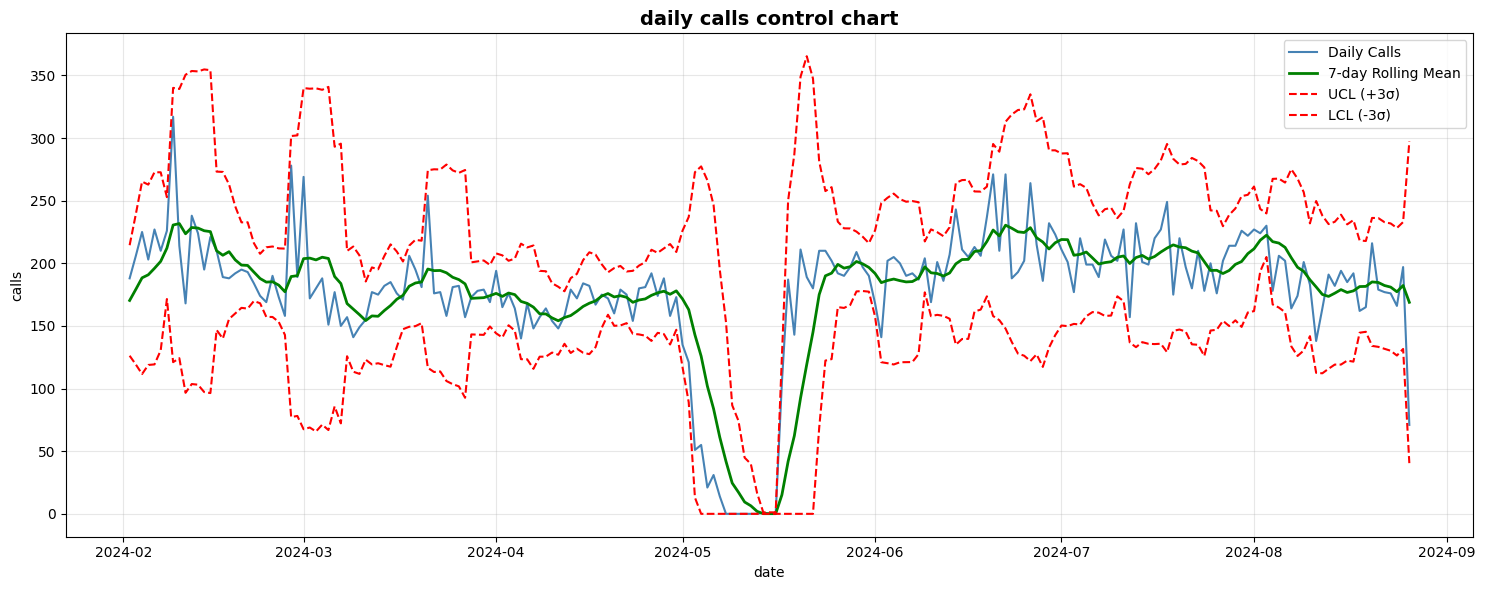

In [118]:
def prepare_daily_control_data(df, ts_col='timestamp', window=7):
    ts = pd.to_datetime(df[ts_col], errors='coerce', utc=True)
    daily = pd.Series(1, index=ts).dropna().resample('D').sum().fillna(0)

    center = daily.rolling(window=window, min_periods=3).mean()
    sigma = daily.rolling(window=window, min_periods=3).std(ddof=0)
    ucl = center + 3 * sigma
    lcl = (center - 3 * sigma).clip(lower=0)

    result = pd.DataFrame({'calls': daily, 'center': center, 'ucl': ucl, 'lcl': lcl}).dropna()
    result['is_out_of_control'] = (result['calls'] > result['ucl']) | (result['calls'] < result['lcl'])
    return result


def plot_daily_control_chart(df, ts_col='timestamp', window=7):
    ctrl = prepare_daily_control_data(df, ts_col=ts_col, window=window)

    plt.figure(figsize=(15, 6))
    plt.plot(ctrl.index, ctrl['calls'], label='Daily Calls', color='steelblue')
    plt.plot(ctrl.index, ctrl['center'], label=f'{window}-day Rolling Mean', color='green', linewidth=2)
    plt.plot(ctrl.index, ctrl['ucl'], label='UCL (+3σ)', color='red', linestyle='--')
    plt.plot(ctrl.index, ctrl['lcl'], label='LCL (-3σ)', color='red', linestyle='--')

    out_points = ctrl[ctrl['is_out_of_control']]
    if not out_points.empty:
        plt.scatter(out_points.index, out_points['calls'], color='crimson', s=40, zorder=5, label='Out-of-control')

    plt.title('daily calls control chart', fontsize=14, fontweight='bold')
    plt.xlabel('date')
    plt.ylabel('calls')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_daily_control_chart(historyCall_df_cleaned)

6. unknown data quality map

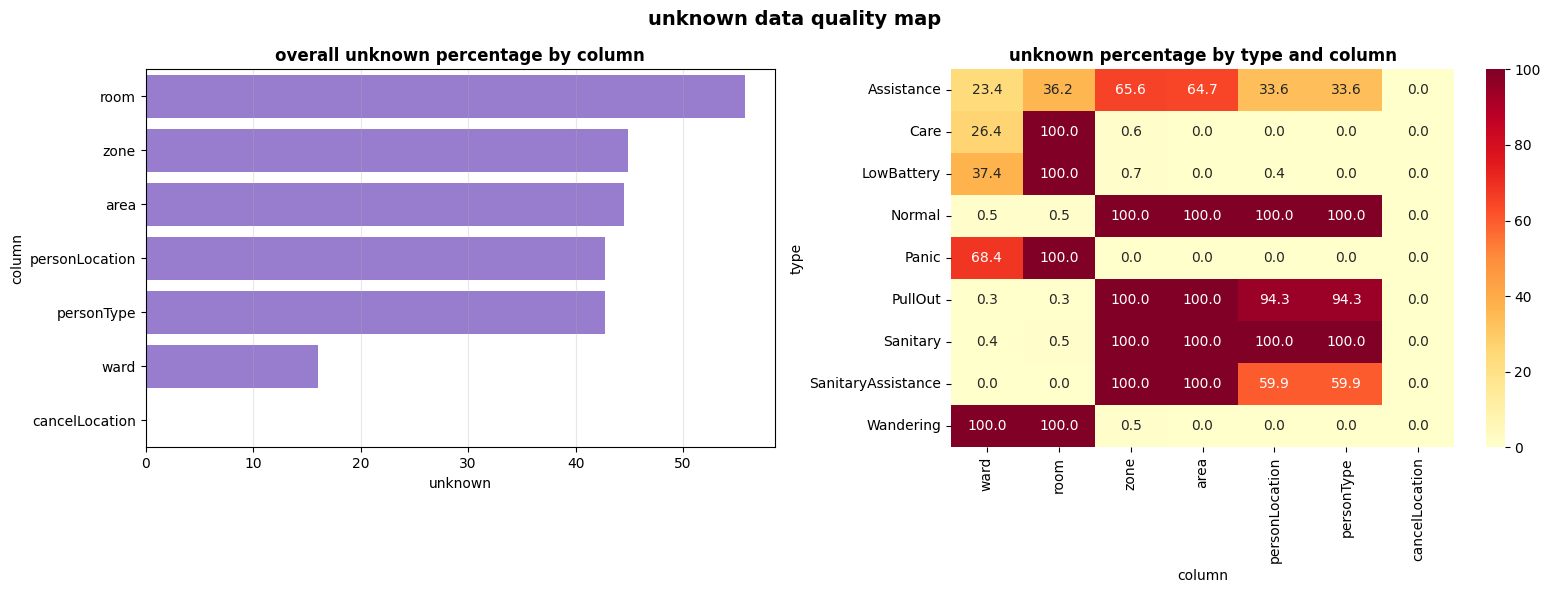

In [119]:
def compute_unknown_rate(series):
    unknown_tokens = {'unknown', 'Unknown', 'n/a', 'N/A', 'na', 'NA', '', 'None', 'none'}
    as_str = series.astype(str)
    return as_str.isin(unknown_tokens).mean() * 100


def prepare_unknown_quality_map(df, columns, type_col='type'):
    overall = {col: compute_unknown_rate(df[col]) for col in columns if col in df.columns}
    overall_df = pd.DataFrame(list(overall.items()), columns=['column', 'unknown_pct'])

    by_type_rows = []
    for t in sorted(df[type_col].dropna().unique()):
        subset = df[df[type_col] == t]
        row = {'type': t}
        for col in columns:
            if col in subset.columns:
                row[col] = compute_unknown_rate(subset[col])
        by_type_rows.append(row)

    by_type_df = pd.DataFrame(by_type_rows)
    return overall_df, by_type_df


def plot_unknown_quality_map(df):
    target_cols = ['ward', 'room', 'zone', 'area', 'personLocation', 'personType', 'cancelLocation']
    overall_df, by_type_df = prepare_unknown_quality_map(df, target_cols)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    sns.barplot(data=overall_df.sort_values('unknown_pct', ascending=False), x='unknown_pct', y='column', ax=axes[0], color='mediumpurple')
    axes[0].set_title('overall unknown percentage by column', fontweight='bold')
    axes[0].set_xlabel('unknown')
    axes[0].set_ylabel('column')
    axes[0].grid(axis='x', alpha=0.3)

    heatmap_df = by_type_df.set_index('type').fillna(0)
    sns.heatmap(heatmap_df, cmap='YlOrRd', annot=True, fmt='.1f', ax=axes[1])
    axes[1].set_title('unknown percentage by type and column', fontweight='bold')
    axes[1].set_xlabel('column')
    axes[1].set_ylabel('type')

    plt.suptitle('unknown data quality map', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_unknown_quality_map(historyCall_df_cleaned)

7. ward workload

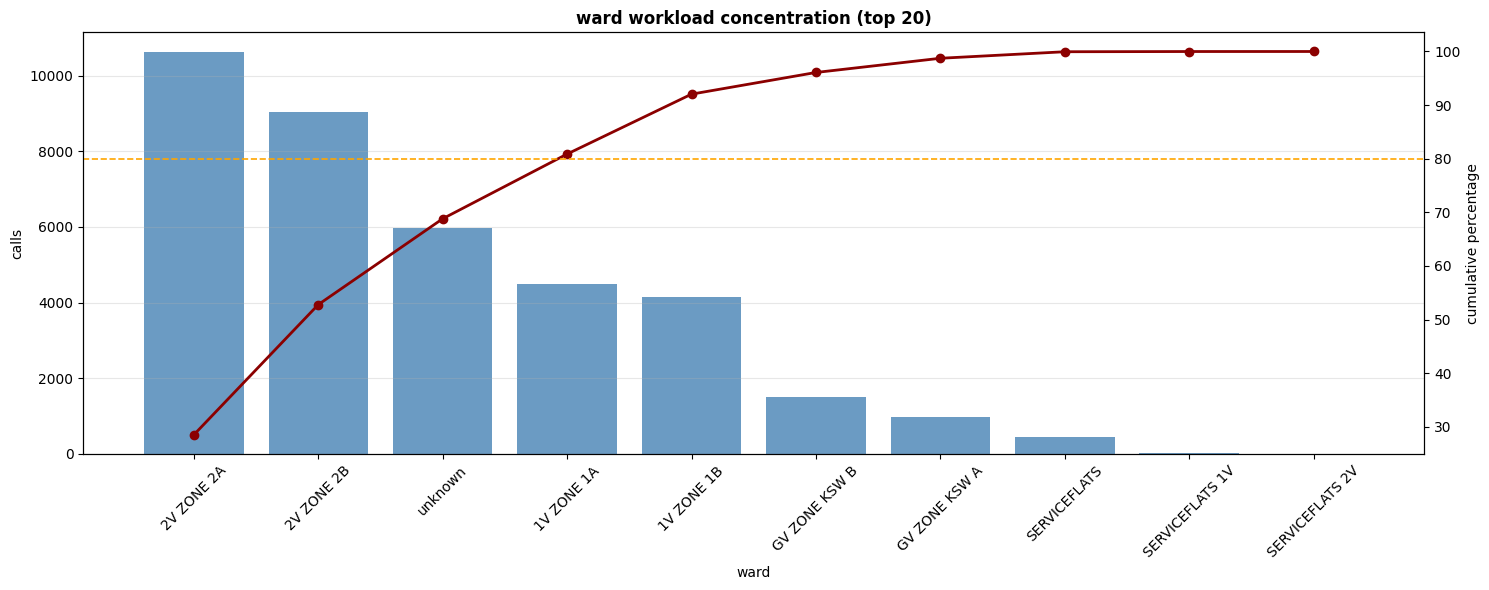

In [120]:
def prepare_ward_concentration(df, ward_col='ward'):
    ward_counts = df[ward_col].astype(str).value_counts().reset_index()
    ward_counts.columns = ['ward', 'calls']
    ward_counts['cum_pct'] = ward_counts['calls'].cumsum() / ward_counts['calls'].sum() * 100
    return ward_counts


def plot_ward_workload_concentration(df, ward_col='ward', top_n=20):
    ward_counts = prepare_ward_concentration(df, ward_col=ward_col)
    top = ward_counts.head(top_n).copy()

    fig, ax1 = plt.subplots(figsize=(15, 6))
    ax2 = ax1.twinx()

    ax1.bar(top['ward'], top['calls'], color='steelblue', alpha=0.8)
    ax2.plot(top['ward'], top['cum_pct'], color='darkred', marker='o', linewidth=2)

    ax1.set_title(f'ward workload concentration (top {top_n})', fontweight='bold')
    ax1.set_xlabel('ward')
    ax1.set_ylabel('calls')
    ax2.set_ylabel('cumulative percentage')
    ax2.axhline(80, color='orange', linestyle='--', linewidth=1.2)

    ax1.tick_params(axis='x', rotation=45)
    ax1.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_ward_workload_concentration(historyCall_df_cleaned)

8. response time and priority distribution

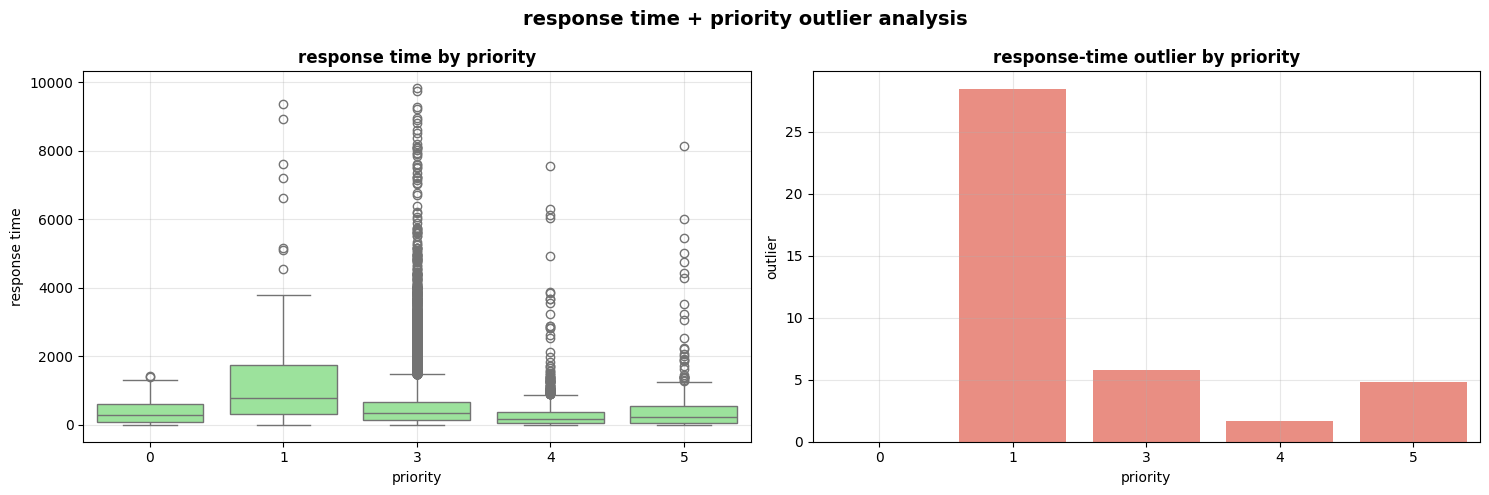

IQR bounds: lower=-668.00, upper=1460.00


In [121]:
def prepare_response_time_seconds(df, response_col='responseTime'):
    response_raw = df[response_col].astype(str).str.extract(r'([-+]?\d*\.?\d+)')[0]
    response_numeric = pd.to_numeric(response_raw, errors='coerce')

    median_val = response_numeric.dropna().median() 
    if pd.notna(median_val) and median_val > 1e6:   # convert seconds if median suggests ticks
        response_seconds = response_numeric / 1e7
    else:
        response_seconds = response_numeric

    return response_seconds


def get_iqr_bounds(series, multiplier=1.5):
    clean = series.dropna()
    q1 = clean.quantile(0.25)
    q3 = clean.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - multiplier * iqr
    upper = q3 + multiplier * iqr
    return lower, upper


def plot_response_priority_outliers(df, priority_col='priority', response_col='responseTime'):
    tmp = df.copy()
    tmp['response_time_sec'] = prepare_response_time_seconds(tmp, response_col=response_col)

    lower, upper = get_iqr_bounds(tmp['response_time_sec'])
    tmp['is_response_outlier'] = (tmp['response_time_sec'] < lower) | (tmp['response_time_sec'] > upper)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    sns.boxplot(data=tmp, x=priority_col, y='response_time_sec', ax=axes[0], color='lightgreen')
    axes[0].set_title('response time by priority', fontweight='bold')
    axes[0].set_xlabel('priority')
    axes[0].set_ylabel('response time')
    axes[0].grid(alpha=0.3)

    outlier_summary = tmp.groupby(priority_col)['is_response_outlier'].mean().mul(100).reset_index(name='outlier_pct')
    sns.barplot(data=outlier_summary, x=priority_col, y='outlier_pct', ax=axes[1], color='salmon')
    axes[1].set_title('response-time outlier by priority', fontweight='bold')
    axes[1].set_xlabel('priority')
    axes[1].set_ylabel('outlier')
    axes[1].grid(alpha=0.3)

    plt.suptitle('response time + priority outlier analysis', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    print(f'IQR bounds: lower={lower:.2f}, upper={upper:.2f}')

plot_response_priority_outliers(historyCall_df_cleaned)